In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


### Dataset Load

In [2]:
df = pd.read_csv("Unemployment in India.csv")
df.columns = df.columns.str.strip()
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


### Data Inspection

In [3]:
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    str    
 1   Date                                     740 non-null    str    
 2   Frequency                                740 non-null    str    
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB

Missing Values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed         

,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),740.0,1.178795e+01,1.072130e+01,0.00,4.657500e+00,8.35,1.588750e+01,76.74
Estimated Employed,740.0,7.204460e+06,8.087988e+06,49420.00,1.190404e+06,4744178.50,1.127549e+07,45777509.00
Estimated Labour Participation Rate (%),740.0,4.263012e+01,8.111094e+00,13.33,3.806250e+01,41.16,4.550500e+01,72.57


### Data Cleaning

In [4]:
df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(), dayfirst=True, errors="coerce")
numeric_cols = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["Region"] = df["Region"].astype("string").str.strip()
df = df.dropna(subset=["Region", "Date"] + numeric_cols).copy()
df = df.drop_duplicates()
df = df.sort_values("Date")
print("Cleaned Dataset Shape:", df.shape)
display(df.head())

Cleaned Dataset Shape: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
290,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
276,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
257,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
243,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


### Exploratory Data Analysis (EDA)

In [5]:
print("Total Regions:", df["Region"].nunique())

print("\nRegions:")
print(df["Region"].unique())

print("\nDate Range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nAverage Unemployment Rate:")
print(df["Estimated Unemployment Rate (%)"].mean())

print("\nState-wise Average Unemployment:")
display(df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False).to_frame("Average Unemployment Rate (%)"))

Total Regions: 28

Regions:
<StringArray>
[  'Andhra Pradesh',        'Telangana',       'Tamil Nadu',
        'Rajasthan',           'Punjab',       'Puducherry',
           'Odisha',        'Meghalaya',      'Maharashtra',
   'Madhya Pradesh',           'Kerala',          'Tripura',
        'Karnataka',        'Jharkhand',  'Jammu & Kashmir',
    'Uttar Pradesh', 'Himachal Pradesh',          'Haryana',
      'Uttarakhand',          'Gujarat',              'Goa',
            'Delhi',     'Chhattisgarh',       'Chandigarh',
            'Bihar',            'Assam',      'West Bengal',
           'Sikkim']
Length: 28, dtype: string

Date Range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00

Average Unemployment Rate:
11.787945945945943

State-wise Average Unemployment:


,Average Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


### Line Chart

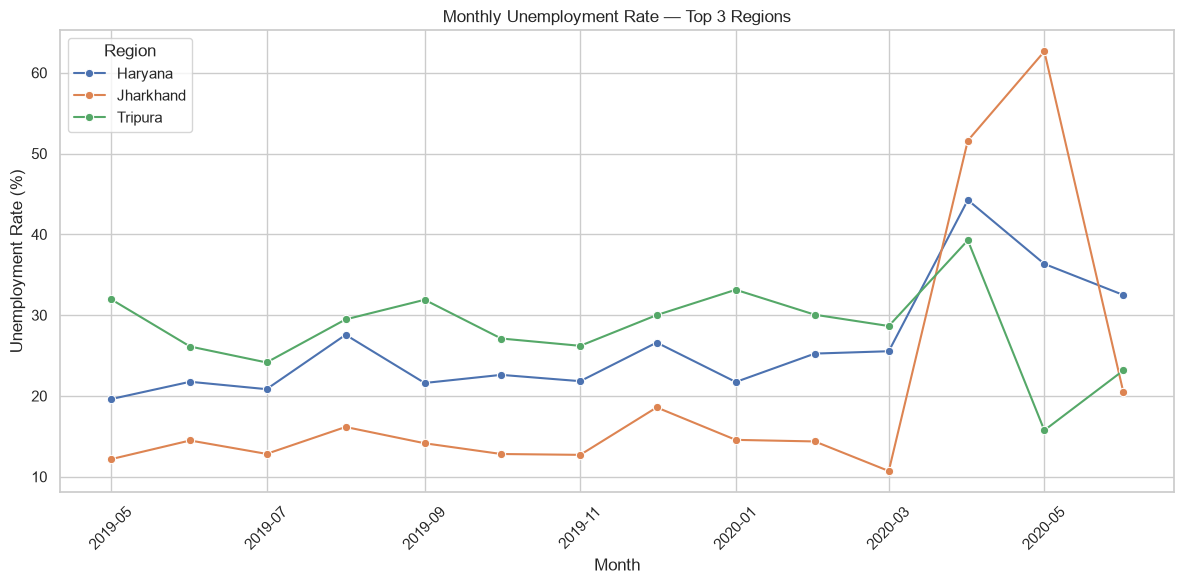

In [6]:
monthly_data = (df.assign(Month=df["Date"].dt.to_period("M").dt.to_timestamp()).groupby(["Month", "Region"], as_index=False)["Estimated Unemployment Rate (%)"].mean())
top3 = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().nlargest(3).index)
plot_data = monthly_data[monthly_data["Region"].isin(top3)]
sns.lineplot(data=plot_data, x="Month", y="Estimated Unemployment Rate (%)", hue="Region", marker="o")
plt.title("Monthly Unemployment Rate — Top 3 Regions")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Bar Chart

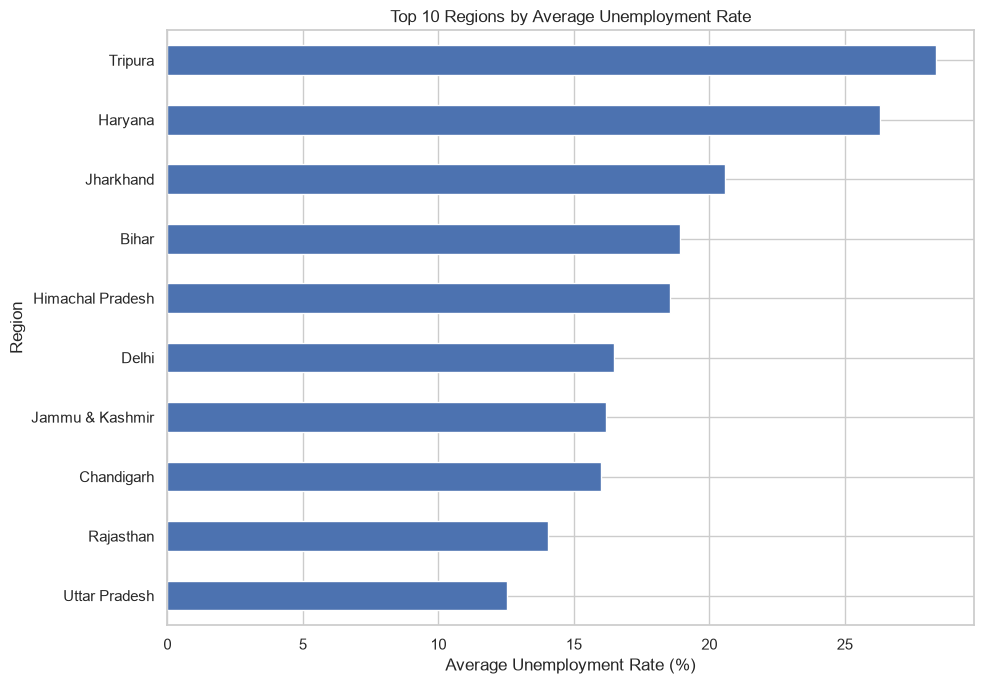

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64

In [7]:
top10 = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().nlargest(10).sort_values())
top10.plot(kind="barh", figsize=(10, 7))
plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()
display(top10.sort_values(ascending=False))

### Correlation Heatmap

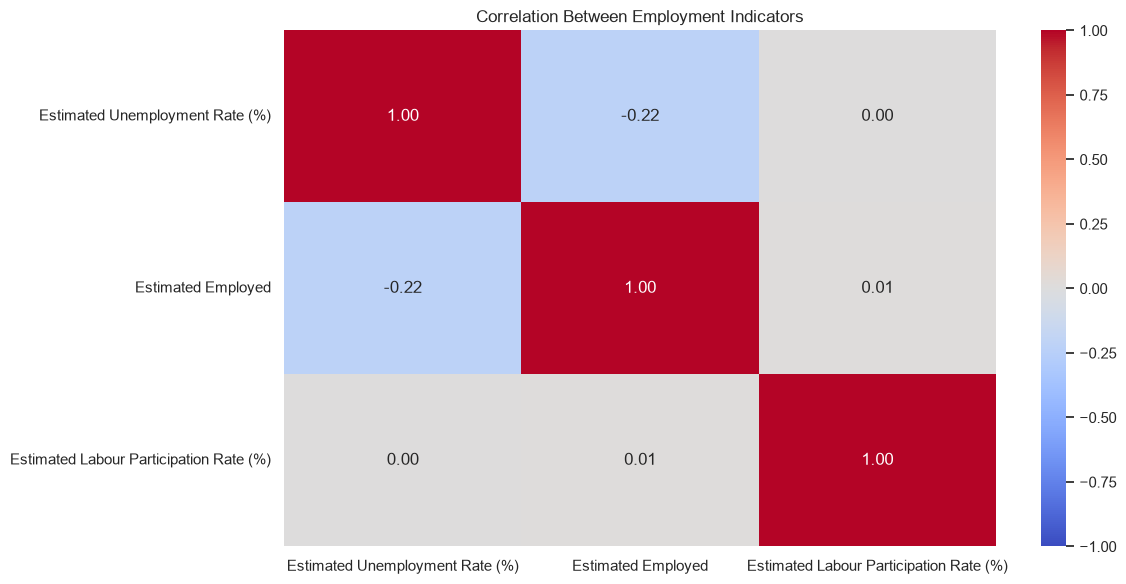

In [8]:
corr_cols = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
correlation = df[corr_cols].corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

### Pre-COVID vs Post-COVID Analysis

COVID_Period
Pre-COVID      9.509534
Post-COVID    17.774363
Name: Estimated Unemployment Rate (%), dtype: float64


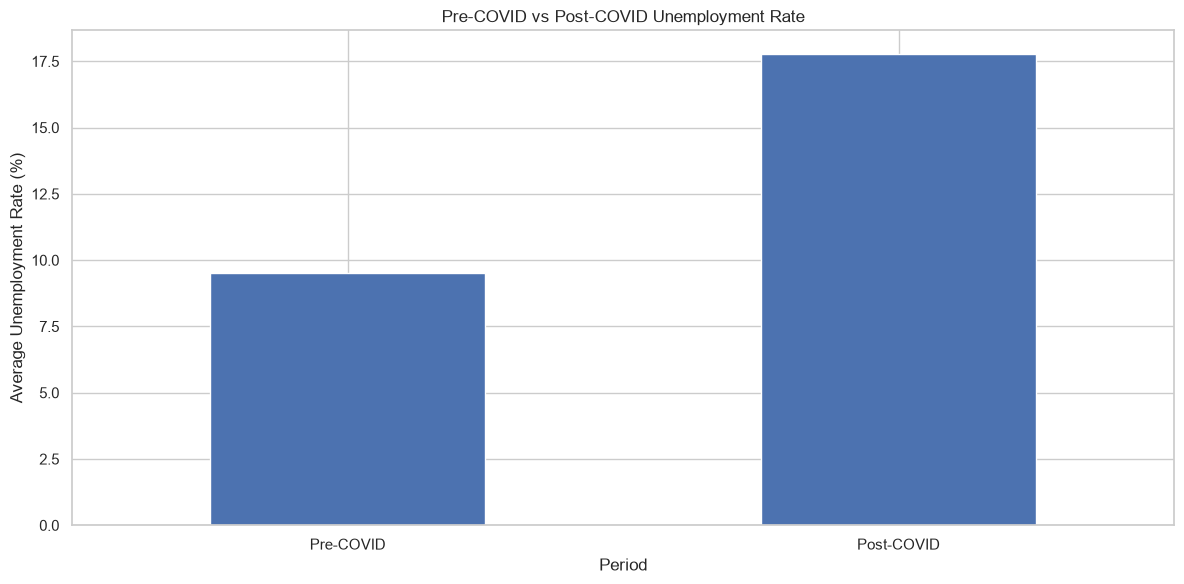

In [9]:
cutoff_date = pd.Timestamp("2020-03-25")
df["COVID_Period"] = np.where(df["Date"] < cutoff_date, "Pre-COVID", "Post-COVID")
period_avg = (df.groupby("COVID_Period")["Estimated Unemployment Rate (%)"].mean().reindex(["Pre-COVID", "Post-COVID"]))
print(period_avg)
period_avg.plot(kind="bar", rot=0)
plt.title("Pre-COVID vs Post-COVID Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

### Monthly Trend Analysis

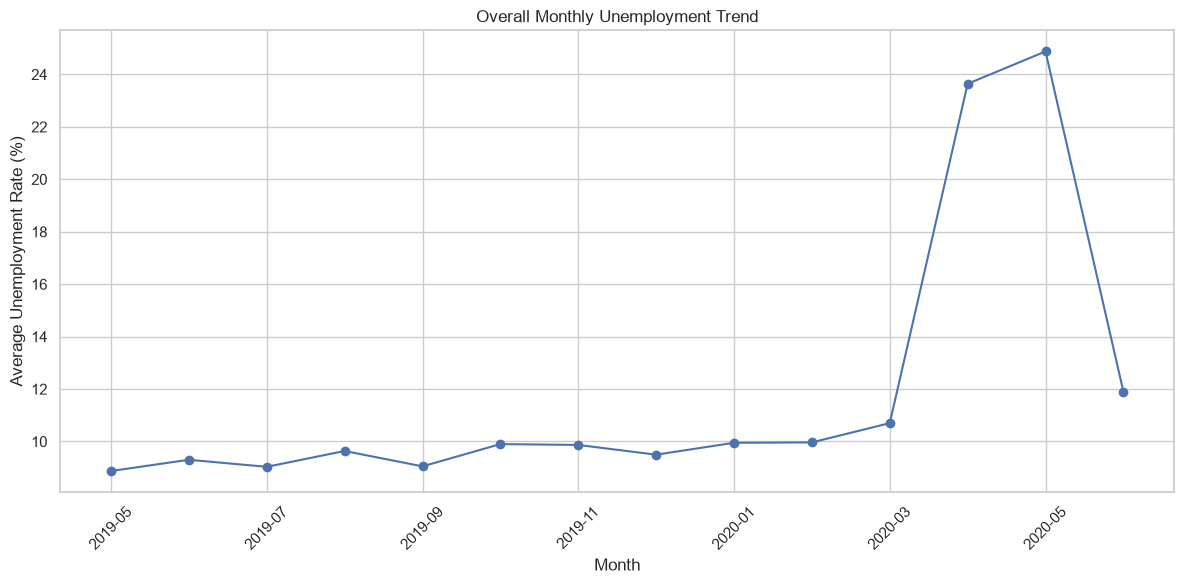

In [10]:
monthly_trend = (df.groupby(df["Date"].dt.to_period("M"))["Estimated Unemployment Rate (%)"].mean())
monthly_trend.index = monthly_trend.index.astype(str)
monthly_trend.plot(marker="o")
plt.title("Overall Monthly Unemployment Trend")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()